Dataset Shape: (10000, 12)

Churn by Engagement:
 IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64

Churn by Product Usage:
 NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64

Churn by Balance Segment:
 BalanceSegment
Zero      13.823611
Low       34.666667
Medium    19.880716
High      25.015740
Name: Exited, dtype: float64

Churn by Credit Score:
 CreditBand
Poor         23.639191
Fair         21.075920
Good         19.307379
Excellent    19.689922
Name: Exited, dtype: float64


/tmp/ipykernel_7034/532740902.py:44: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  balance_risk = df.groupby('BalanceSegment')['Exited'].mean() * 100
/tmp/ipykernel_7034/532740902.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  credit_risk = df.groupby('CreditBand')['Exited'].mean() * 100


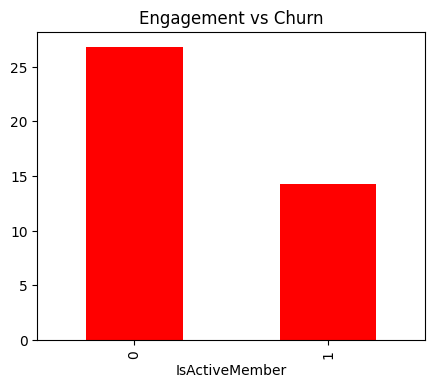

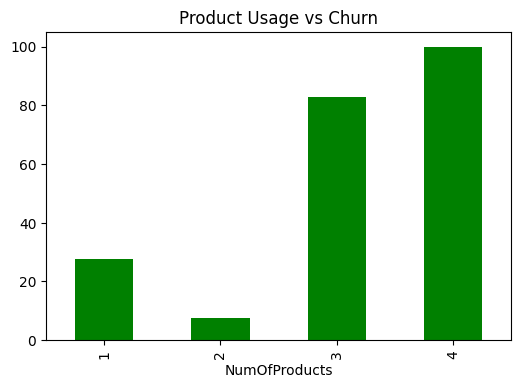

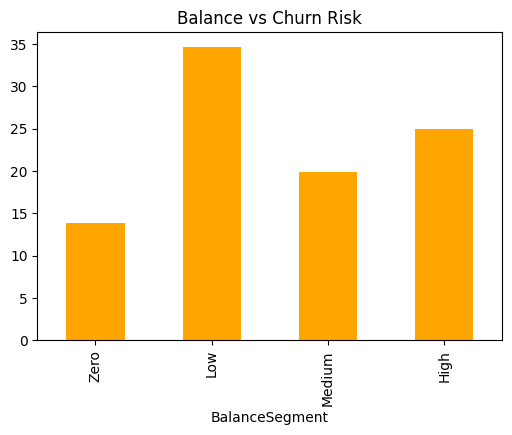

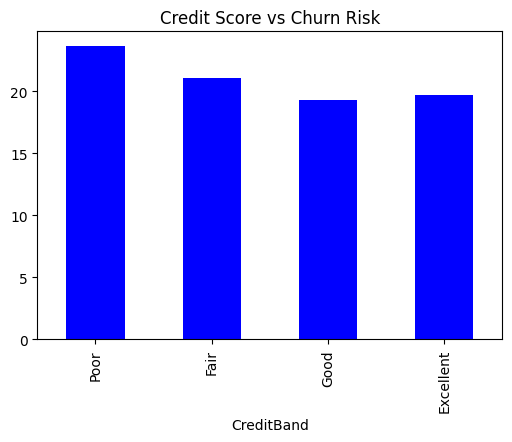

In [2]:
# ==========================================
# CUSTOMER ENGAGEMENT & PRODUCT UTILIZATION ANALYTICS
# RETENTION STRATEGY (EUROPEAN BANKING)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# LOAD DATASET
# -------------------------
df = pd.read_csv("European_Bank.csv.csv")  # change if needed

# -------------------------
# CLEANING
# -------------------------
df = df.drop(columns=[col for col in ['CustomerId', 'Surname'] if col in df.columns])

print("Dataset Shape:", df.shape)

# -------------------------
# ENGAGEMENT ANALYSIS
# -------------------------
df['IsActiveMember'] = df['IsActiveMember'].astype(int)

engagement = df.groupby('IsActiveMember')['Exited'].mean() * 100
print("\nChurn by Engagement:\n", engagement)

# -------------------------
# PRODUCT USAGE ANALYSIS
# -------------------------
product_usage = df.groupby('NumOfProducts')['Exited'].mean() * 100
print("\nChurn by Product Usage:\n", product_usage)

# -------------------------
# BALANCE SEGMENT
# -------------------------
df['BalanceSegment'] = pd.cut(df['Balance'],
                              bins=[-1,0,50000,100000,200000],
                              labels=['Zero','Low','Medium','High'])

balance_risk = df.groupby('BalanceSegment')['Exited'].mean() * 100
print("\nChurn by Balance Segment:\n", balance_risk)

# -------------------------
# CREDIT SCORE ANALYSIS
# -------------------------
df['CreditBand'] = pd.cut(df['CreditScore'],
                          bins=[300,500,650,800,900],
                          labels=['Poor','Fair','Good','Excellent'])

credit_risk = df.groupby('CreditBand')['Exited'].mean() * 100
print("\nChurn by Credit Score:\n", credit_risk)

# -------------------------
# VISUALS
# -------------------------

# Engagement
plt.figure(figsize=(5,4))
engagement.plot(kind='bar', color='red')
plt.title("Engagement vs Churn")
plt.show()

# Product usage
plt.figure(figsize=(6,4))
product_usage.plot(kind='bar', color='green')
plt.title("Product Usage vs Churn")
plt.show()

# Balance
plt.figure(figsize=(6,4))
balance_risk.plot(kind='bar', color='orange')
plt.title("Balance vs Churn Risk")
plt.show()

# Credit
plt.figure(figsize=(6,4))
credit_risk.plot(kind='bar', color='blue')
plt.title("Credit Score vs Churn Risk")
plt.show()